In [1]:
#import nbimporter
#import CLN
%run ./CLN.ipynb
import scipy.special as sp_special

def _mono_terms(expr, r):
    # expr を r の単項式の和として (係数, 指数) のリストで返す
    # (sp.expand は a**(2-2n) 等を書き換えてしまうので使わない)
    expr = sp.sympify(expr)
    if isinstance(expr, sp.Add):
        out = []
        for t in expr.args:
            out.extend(_mono_terms(t, r))
        return out
    if isinstance(expr, sp.Mul):
        out = [(sp.S.One, sp.S.Zero)]
        for f in expr.args:
            ft = _mono_terms(f, r)
            out = [(c1 * c2, e1 + e2) for c1, e1 in out for c2, e2 in ft]
        return out
    if isinstance(expr, sp.Pow):
        if expr.base == r:
            return [(sp.S.One, expr.exp)]
        if isinstance(expr.exp, sp.Integer) and expr.exp >= 0:
            bt = _mono_terms(expr.base, r)
            out = [(sp.S.One, sp.S.Zero)]
            for _ in range(int(expr.exp)):
                out = [(c1 * c2, e1 + e2) for c1, e1 in out for c2, e2 in bt]
            return out
        return [(expr, sp.S.Zero)]
    if expr == r:
        return [(sp.S.One, sp.S.One)]
    return [(expr, sp.S.Zero)]


class CLN_Sphere(CLN):
    def __init__(self, mode='H', n_sph=1, a=0.01, sigma=1e6, mur=1):
        super().__init__(mode, a, sigma, mur)
        self.mode = 'H'
        self.C = CoordSys3D('C', transformation='spherical')
        self.x = sp.symbols('r', positive=True)
        self.y = sp.symbols('\\theta', real=True)

        self.sym_n = sp.symbols('n', positive=True, integer=True)

        if self.mode == 'H': self.formulation = self.formulationH
        self.n_value = n_sph
        import scipy.special as sp_special
        self.namespace = {
                'besseli': lambda v, x: sp_special.iv(v, x),
                'besselj': lambda v, x: sp_special.jv(v, x),
                'bessely': lambda v, x: sp_special.yv(v, x),
                'besselk': lambda v, x: sp_special.kv(v, x),
                'sqrt': np.sqrt,
                'Pi': np.pi
            }
        self.subs_parameters = {self.a: self.default_a,
                                self.sigma: self.default_sigma,
                                self.mu: self.default_mu,
                                self.sym_n: self.n_value}

    def We(self, E):
        return self.sigma * E**2

    def Wh(self, H):
        Hr = H[0]
        Ht = H[1]
        n = self.n_value
        return self.mu * (Hr**2 / (n * (n + 1)) + Ht**2)

    def solveCurlCurl_A(self, J, Es, Hs=0):
        r = self.x
        a = self.a
        mu = self.mu
        n = self.n_value
        # 静的方程式 Az'' + (2/r) Az' - n(n+1)/r^2 Az = -mu J を
        # 単項式 J = c r^m に対する Az = d r^(m+2) の未定係数法で解く
        # (2015年論文の多項式展開そのもの; 同次解の正則解は r^n)
        try:
            Azp = 0
            for c, e in _mono_terms(J, r):
                if c == 0:
                    continue
                q = e + 2
                Azp = Azp - mu * c * r**q / (q * (q + 1) - n * (n + 1))
            C1 = sp.symbols('C1')
            sol = Azp + C1 * r**n
            Ht_a = -(sol.subs(r, a) + a * sol.diff(r).subs(r, a)) / (mu * a)
            sol = sol.subs(C1, sp.solve(sp.Eq(Ht_a, Hs), C1)[0])
        except Exception:
            Az = sp.Function('Az')(r)
            Ht = -(Az + r * sp.Derivative(Az, r)) / (mu * r)
            Hr = -n * (n + 1) * Az / (mu * r)
            curl_H = (sp.Derivative(r * Ht, r) - Hr) / r
            sol = sp.dsolve(sp.Eq(curl_H, J), Az).rhs
            sol = self.remove_divergence(sol, 0)
            Ht_a = -(sol.subs(r, a) + a * sol.diff(r).subs(r, a)) / (mu * a)
            c_syms = [s for s in sol.free_symbols if s.name.startswith('C')]
            sol = sol.subs(sp.solve([sp.Eq(Ht_a, Hs)], c_syms))

        Az = sol
        Ht = -(Az + r * sp.diff(Az, r)) / (mu * r)
        Hr = -n * (n + 1) * Az / (mu * r)
        Az = sp.cancel(Az)
        Ht = sp.cancel(Ht)
        Hr = sp.cancel(Hr)
        return np.array([Hr, Ht, 0]), Az

    def solveAmpere(self, J, Hs=0):
        # curl H = J （J は J_phi のプロファイル）、div B = 0 を解く。
        # u = r Ht と置くと、div B = 0 と合わせて
        #   (r^2 u')' - n(n+1) u = (r^3 J)'
        # となる。単項式 J = c r^m に対して u = d r^(m+2)、
        # d = c (m+3) / ((m+2)(m+3) - n(n+1)) （未定係数法）。
        # 同次解の正則解は r^n。Hr = u' - r J、Ht = u / r。
        # 境界条件は Ht(a) = Hs。
        r = self.x
        a = self.a
        n = self.n_value
        up = 0
        for c, e in _mono_terms(J, r):
            if c == 0:
                continue
            q = e + 2
            up = up + c * (e + 3) * r**q / (q * (q + 1) - n * (n + 1))
        C1 = sp.symbols('C1')
        u = up + C1 * r**n
        u = u.subs(C1, sp.solve(sp.Eq(u.subs(r, a), a * Hs), C1)[0])
        Ht = u / r
        Hr = sp.diff(u, r) - r * J
        return np.array([sp.cancel(Hr), sp.cancel(Ht), 0])

    def solveFaraday(self, B, Es=0):
        # curl E = -B から E_phi のプロファイル e を求める。
        # theta 成分: e + r e' = r B_t、すなわち (r e)' = r B_t を
        # 項別に積分する（原点で r e = 0）。r 成分とは B の発散なし
        # 条件を通じて整合する。Es は H モードでは用いない（円柱版と同じ）。
        r = self.x
        Bt = B[1]
        e_prof = 0
        for c, m in _mono_terms(Bt, r):
            if c == 0:
                continue
            e_prof = e_prof + c * r**(m + 1) / (m + 2)
        return e_prof

    def buildCLN_T(self, nmax=8, by_integ=False):
        # 基底クラスの buildCLN_T は H がスカラー前提で
        # L[n] = Vintegrate(mu * H^2) としている。球では H が
        # (Hr, Ht) の2成分で重み Wh が必要なので、L の計算だけ
        # Wh に置き換える（他は基底クラスと同一）。
        self.by_integ = by_integ
        sigma, mu, s = self.sigma, self.mu, self.s
        dZ, dZinv = sp.symbols('dZ dZinv')
        Z = sp.Function('Z')(s)
        E = {}; H = {}; R = {}; L = {}
        T = {}
        if self.mode == 'E': n = 0
        elif self.mode == 'H': n = -1
        while n <= nmax:
            if n >= 0:
                if n == 0:
                    B = 0; Es = 1; Hs = 0; Z = 1 / dZinv
                else:
                    B = mu * H[n - 1] / L[n - 1]; Es = 0; Hs = 0
                E[n], T[n] = self.solveCurlCurl_T(B, Es, Hs)
                if n > 1:
                    E[n] += E[n - 2]
                    T[n] += T[n - 2]
                R[n] = 1 / self.Vintegrate(self.We(E[n]))
                Z = Z.subs(dZinv, 1 / (dZ + R[n]))
            n = n + 1
            if n > nmax: break
            if n >= 0:
                if n == 0:
                    J = 0; Hs = 1; Z = dZ
                    H[n] = self.solveAmpere(J, Hs)
                else:
                    J = sigma * E[n - 1] * R[n - 1]
                    H[n] = T[n - 1] * R[n - 1]
                    if n > 1: H[n] += H[n - 2]
                L[n] = self.Vintegrate(self.Wh(H[n]))
                Z = Z.subs(dZ, 1 / (1 / (s * L[n]) + dZinv))
            n = n + 1
        Z = Z.subs({dZ: 0, dZinv: 0})
        self.R = R
        self.L = L
        return R, L, T, E, H, Z

    def Vintegrate(self, integrand):
        # integrand は r の単項式の和 (指数に n を含みうる) なので項別に積分する
        r = self.x
        a = self.a
        total = 0
        for c, e in _mono_terms(integrand, r):
            total = total + c * a**(e + 3) / (e + 3)
        return total / a**2


# 球の $H_n$ モード (CLN_Sphere)

半径 $a$ の球に対する $H_n$ モード ($n \ge 1$)。展開は $m$ に依らない。
$n=1$ ($H_{10}$) が一様磁場を加えた場合に相当する。

根拠: 亀有昭久「直交曲線座標系における多項式展開による渦電流の解析」
電気学会 SA-15-84 / RM-15-122 (2015) の §6 (球の場合)。

固有数列 (同論文 (6.7)): $\kappa_i = (n+1),\ (2n+3),\ (2n+5),\ \dots,\ (2n+1+2i),\ \dots$
$n=1$ では $2, 5, 7, 9, 11, \dots$

## $W_h$ の $H_r$ 成分に対する重み $1/(n(n+1))$ の導出

出発点は論文 (SA-15-84 / RM-15-122, 2015) の直交関係 (6.6)。論文では $\Phi, U, V$ が表面で単位規格化されており ((2.11))、その係数 $G, F$ に対して、$\hat{G} = G\xi^{n-1}$, $\hat{F} = F\xi^{n-1}$ と置くと

$$\int_0^1 \left[ n(n+1)\, \hat{G}_{2i} \hat{G}_{2j} + \hat{F}_{2i} \hat{F}_{2j} \right] \xi^2 d\xi = \frac{1}{\kappa_{2i}} \delta_{ij}$$

である。$n(n+1)$ は (6.1) の $H_r = \sqrt{n(n+1)}\, G \xi^{n-1} \Phi$ にある prefactor の2乗である。

一方、コードのプロファイルは非規格化パターンの係数である ($m=0$)：

$$H_r = H_r(r) P_n(\cos\theta), \qquad H_\theta = H_t(r)\, \partial_\theta P_n(\cos\theta), \qquad E_\phi = e(r)\, \partial_\theta P_n(\cos\theta)$$

$\Phi = \sqrt{(2n+1)/(4\pi)}\, P_n(\cos\theta)$、$U_\theta = (\partial_\theta \Phi)/\sqrt{n(n+1)}$ であるから、係数の換算は

$$\hat{G} = H_r \cdot \frac{\sqrt{4\pi/(2n+1)}}{\sqrt{n(n+1)}}, \qquad \hat{F} = H_t \cdot \sqrt{4\pi/(2n+1)} \cdot \sqrt{n(n+1)}$$

($E$ 側の係数 $\hat{F}'$ も $e$ を用いて同形)。これらを (6.6) に代入すると

$$n(n+1)\hat{G}^2 = H_r^2 \cdot \frac{4\pi}{2n+1}, \qquad \hat{F}^2 = n(n+1) H_t^2 \cdot \frac{4\pi}{2n+1}, \qquad \hat{F}'^2 = n(n+1) e^2 \cdot \frac{4\pi}{2n+1}$$

すなわち論文の内積は、コードのプロファイルでは $H$ 側・$E$ 側に**共通の定数** $n(n+1)\cdot 4\pi/(2n+1)$ が全体に掛かった形になる。共通定数は梯子の比に影響せず、残りは $Vintegrate = \int_0^a (\cdot)\, r^2 dr / a^2$ の規格化 ($L_c = \mu a$, $R_c = 1/(\sigma a)$) に吸収される。よって

$$W_h = \mu \left[ \frac{H_r^2}{n(n+1)} + H_t^2 \right], \qquad W_e = \sigma e^2$$

と置けば論文の内積と等価になる。$1/(n(n+1))$ は、(6.1) の $\sqrt{n(n+1)}$ と $U$ の定義の $1/\sqrt{n(n+1)}$ を、規格化なしのパターンへ換算したときの残りである。

検算：この重みにより $L_0 = \mu a / (n+1)$、すなわち $\kappa_0 = n+1$ が得られる（等重みでは $n=1$ で $\kappa_0 = 12/5$ となり (6.7) に一致しない）。

## 静的ステップの未定係数法による解法 (`solveCurlCurl_A`)

各段の静的方程式は

$$A_z'' + \frac{2}{r} A_z' - \frac{n(n+1)}{r^2} A_z = -\mu J, \qquad J = \sum_m c_m r^m$$

である。再帰の中では $J$ は常に単項式の有限和であり（$E, H$ のプロファイルが $r^n, r^{n+2}, \dots$ の和）、解も同形に取ることができる。

**特殊解**：単項式 $J = c\, r^m$ に対して $A_z = d\, r^{m+2}$ と置く。$r^q$ に対して左辺は $\left[ q(q+1) - n(n+1) \right] r^{q-2}$ となるから

$$d = \frac{-\mu c}{(m+2)(m+3) - n(n+1)}$$

**同次解**：$A_z = r^q$ と置くと $q(q+1) = n(n+1)$、すなわち $q = n$ または $q = -n-1$。原点で発散する $r^{-n-1}$ を除き（`dsolve` 版の `remove_divergence` に対応）、正則解 $C_1 r^n$ を加える。

**境界条件**：残った定数 $C_1$ は表面条件 $H_\theta(a) = H_s$（ただし $H_\theta = -(A_z + r A_z')/(\mu r)$）から決める。

**共鳴しないこと**：分母が $0$ になるのは $m = n-2$ のときだけだが、再帰では $J$ の最低次数は $m = n$（$E_1 \propto r^n$）なので現れない。

これは 2015 年論文の多項式展開そのものであり、`dsolve` による一般解法よりはるかに速い。実装では $J$ の（係数，指数）の組を式の構造から直接取り出している（`_mono_terms`。`sp.expand` は $a^{2-2n}$ 等を書き換えて単項式の形を壊すので使わない）。`Vintegrate` の項別積分 $\int_0^a c\, r^m r^2 dr = c\, a^{m+3}/(m+3)$ も同じ仕組みである。

In [2]:
def formulationA(self, output=True):
    if output:
        display(Markdown("# ***** Hn mode in a sphere (球の H_n モード) *****"))

    r, a, s, sigma, mu, Es = self.x, self.a, self.s, self.sigma, self.mu, self.Es
    n = self.sym_n
    nv = self.n_value
    C = self.C

    Az_c = sp.Function('Az')(C.r)
    w = sp.diff(sp.legendre(nv, sp.cos(C.theta)), C.theta)
    A = Az_c * w * C.k
    B = sp.vector.curl(A)
    H = B / mu
    if output:
        display(Markdown("---"))
        display(Markdown("### **【ステップ 1】磁束密度 $\\mathbf{B}$ と磁界 $\\mathbf{H}$ の定義**"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{A}} = {sp.latex(A)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{B}} = \\nabla \\times \\mathbf{{A}} = {sp.latex(B)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{H}} = \\frac{{\\mathbf{{B}}}}{{\\mu}} = {sp.latex(H)} \\end{{equation}}"))

    curl_H = sp.vector.curl(H)
    if output:
        display(Markdown("---"))
        display(Markdown("### **【ステップ 2】磁界の回転 $\\nabla \\times \\\\mathbf{H}$ の展開**"))
        display(Markdown(f"\\begin{{equation}} \\nabla \\times \\mathbf{{H}} = {sp.latex(curl_H)} \\end{{equation}}"))

    J = -sigma * s * A
    eq = (curl_H.dot(C.k) - J.dot(C.k)) / w * mu
    eq = eq.simplify()

    Az_r = sp.Function('Az')(r)
    eq = eq.subs(C.r, r).subs(Az_c.subs(C.r, r), Az_r)
    eq = sp.Eq(eq, 0)

    if output:
        display(Markdown("---"))
        display(Markdown("### **【ステップ 4】支配方程式　**"))
        display(Markdown(f"\\begin{{equation}} {sp.latex(eq)} \\end{{equation}}"))

    As = -Es / s
    sol = sp.dsolve(eq, Az_r).rhs
    sol = sol.replace(lambda expr: expr.has(sp.bessely), lambda expr: 0)
    sol = sol.replace(lambda expr: expr.has(sp.besselk), lambda expr: 0)
    c_syms = [sy for sy in sol.free_symbols if sy.name.startswith('C')]
    sols = sp.solve(sp.Eq(sol.subs(r, a), As), c_syms)
    if isinstance(sols, dict):
        sub = sols
    elif sols and isinstance(sols[0], (list, tuple)):
        sub = dict(zip(c_syms, sols[0]))
    else:
        sub = dict(zip(c_syms, sols))
    sol = sol.subs(sub)
    sol = sol.simplify()

    alpha_val = sp.sqrt(mu) * sp.sqrt(s) * sp.sqrt(sigma)
    k = sp.Symbol('k', positive=True)
    sol = sol.subs(alpha_val, k)
    Az = sol
    Ez = -s * Az

    Hr = -n * (n + 1) * Az / (r * mu)
    Ht = -(Az + r * sp.Derivative(Az, r).doit()) / (mu * r)
    Ht = Ht.cancel().together().simplify()

    Z_expr = (Ez / Ht).subs(alpha_val, k).subs({r: a}).simplify()
    if output:
        display(Markdown("---"))
        display(Markdown("### **【ステップ 5】解析解（電場・磁界・表面インピーダンス）**"))
        display(Markdown(f"\\begin{{equation}} k = {sp.latex(alpha_val)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} E_\\phi(r) = {sp.latex(Ez)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} H_\\theta(r) = {sp.latex(Ht)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} H_r(r) = {sp.latex(Hr)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} Z = {sp.latex(Z_expr)} \\end{{equation}}"))

    Z_exact_sym = Z_expr.subs(k, alpha_val).simplify()
    return Z_exact_sym


CLN_Sphere.formulationH = formulationA


def formulationT(self, output=True):
    if output:
        display(Markdown("# ***** Hn mode in a sphere (T formulation) *****"))
    r, a, s, sigma, mu = self.x, self.a, self.s, self.sigma, self.mu
    nv = self.n_value
    # T法: H = T と置く。J = curl H、E = J / sigma とし、
    # Faraday curl E = -s mu H を成分ごとに書くと、E_phi の
    # プロファイル e(r) を用いて
    #   Hr = n(n+1) e / (s mu r),   Ht = (e + r e') / (s mu r)
    # となる。これらを Ampere curl H = J に代入すると、e の方程式
    #   e'' + (2/r) e' - (n(n+1)/r^2 + s sigma mu) e = 0
    # が得られる（A法の Az と同じ方程式）。
    # 境界条件は表面で Ht(a) = 1、すなわち e(a) + a e'(a) = s mu a。
    # Z = e(a) / Ht(a) = e(a)。
    e = sp.Function('e')(r)
    eq = sp.Eq(sp.Derivative(e, r, 2) + 2 / r * sp.Derivative(e, r)
               - (nv * (nv + 1) / r**2 + s * sigma * mu) * e, 0)
    sol = sp.dsolve(eq, e).rhs
    sol = sol.replace(lambda expr: expr.has(sp.bessely), lambda expr: 0)
    sol = sol.replace(lambda expr: expr.has(sp.besselk), lambda expr: 0)
    c_syms = [sy for sy in sol.free_symbols if sy.name.startswith('C')]
    sols = sp.solve(sp.Eq((sol + r * sp.diff(sol, r)).subs(r, a), s * mu * a), c_syms)
    if isinstance(sols, dict):
        sub = sols
    elif sols and isinstance(sols[0], (list, tuple)):
        sub = dict(zip(c_syms, sols[0]))
    else:
        sub = dict(zip(c_syms, sols))
    sol = sol.subs(sub).simplify()
    alpha_val = sp.sqrt(mu) * sp.sqrt(s) * sp.sqrt(sigma)
    k = sp.Symbol('k', positive=True)
    sol = sol.subs(alpha_val, k)
    Z_expr = sol.subs({r: a}).simplify()
    if output:
        display(Markdown("---"))
        display(Markdown("### ** analytic solution (T formulation) **"))
        display(Markdown(f"\\begin{{equation}} k = {sp.latex(alpha_val)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} E_\\phi(r) = {sp.latex(sol)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} Z = {sp.latex(Z_expr)} \\end{{equation}}"))
    return Z_expr.subs(k, alpha_val).simplify()


CLN_Sphere.formulationT = formulationT


## 解析解の整理

`dsolve` の生出力は $\sinh/\cosh$ の長い式になるが、球ベッセル関数 $j_n$ を使うと解析解は次の形に整理できる。$\kappa = \sqrt{-s\sigma\mu}$ とする。

$$A_z(r) = -\frac{E_s}{s}\, \frac{j_n(\kappa r)}{j_n(\kappa a)}, \qquad E_\phi = E_s\, \frac{j_n(\kappa r)}{j_n(\kappa a)}$$

$$Z = s\mu a\, \frac{j_n(\kappa a)}{j_n(\kappa a) + \kappa a\, j_n'(\kappa a)} = s\mu a\, \frac{j_n(\kappa a)}{\psi_n'(\kappa a)}, \qquad \psi_n(z) = z j_n(z)$$

$$\mu_r = \frac{Z}{s\mu a} = \frac{j_n(\kappa a)}{\psi_n'(\kappa a)} \;\xrightarrow{\kappa a \to 0}\; \frac{1}{n+1} = \frac{1}{\kappa_0}$$

検証（2026-11-16）：$n=1$ で `formulationH` の `dsolve` 厳密解と相対差 $10^{-15}$ 台（100 Hz–100 kHz）、$n=2$ で CLN（8段）と相対差 $10^{-15}$ 台（100 Hz, 1 kHz）で一致。直流極限 $\mu_r \to 1/(n+1)$ も確認。


### 📊 現在のパラメータ設定
- **モード (`mode`)**: `H`
- **次数 ($n_\theta$)**: `1`
- **半径 (`a`)**: $a$ ( `0.01`)
- **導電率  ($\sigma$)**: ( `1000000.0`)
- **比透磁率 ($\mu_r$)**:   `1.00000000000000`)



# ***** Hn mode in a sphere (球の H_n モード) *****

---

### **【ステップ 1】磁束密度 $\mathbf{B}$ と磁界 $\mathbf{H}$ の定義**

\begin{equation} \mathbf{A} = \left(- \operatorname{Az}{\left(\mathbf{{r}_{C}} \right)} \sin{\left(\mathbf{{theta}_{C}} \right)}\right)\mathbf{\hat{k}_{C}} \end{equation}

\begin{equation} \mathbf{B} = \nabla \times \mathbf{A} = \left(- \frac{2 \operatorname{Az}{\left(\mathbf{{r}_{C}} \right)} \cos{\left(\mathbf{{theta}_{C}} \right)}}{\mathbf{{r}_{C}}}\right)\mathbf{\hat{i}_{C}} + \left(\frac{\mathbf{{r}_{C}} \sin^{2}{\left(\mathbf{{theta}_{C}} \right)} \frac{d}{d \mathbf{{r}_{C}}} \operatorname{Az}{\left(\mathbf{{r}_{C}} \right)} + \operatorname{Az}{\left(\mathbf{{r}_{C}} \right)} \sin^{2}{\left(\mathbf{{theta}_{C}} \right)}}{\mathbf{{r}_{C}} \sin{\left(\mathbf{{theta}_{C}} \right)}}\right)\mathbf{\hat{j}_{C}} \end{equation}

... (31 outputs left out)

<IPython.core.display.Math object>

**【適用する置き換えの式】**

<IPython.core.display.Math object>

Eq(Z_{\text{CLN}}(s), 1/(1/(5*R_c + 1/(1/(9*R_c + 1/(1/(13*R_c + 1/(1/(L_c*s/19 + 17*R_c) + 15/(L_c*s))) + 11/(L_c*s))) + 7/(L_c*s))) + 2/(L_c*s)))

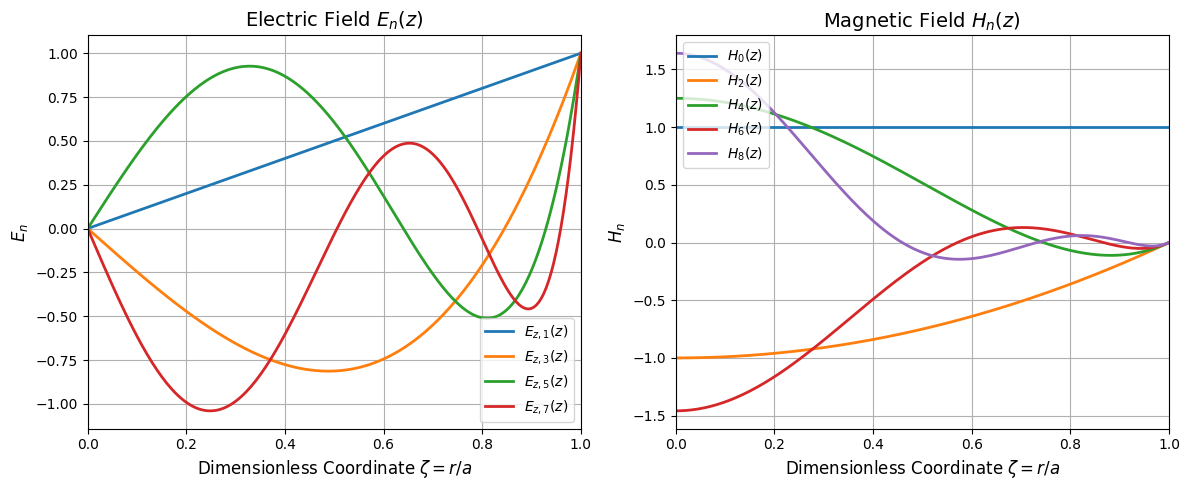

{a: 0.01, sigma: 1000000.0, mu: 4.0e-7*pi, n: 1}


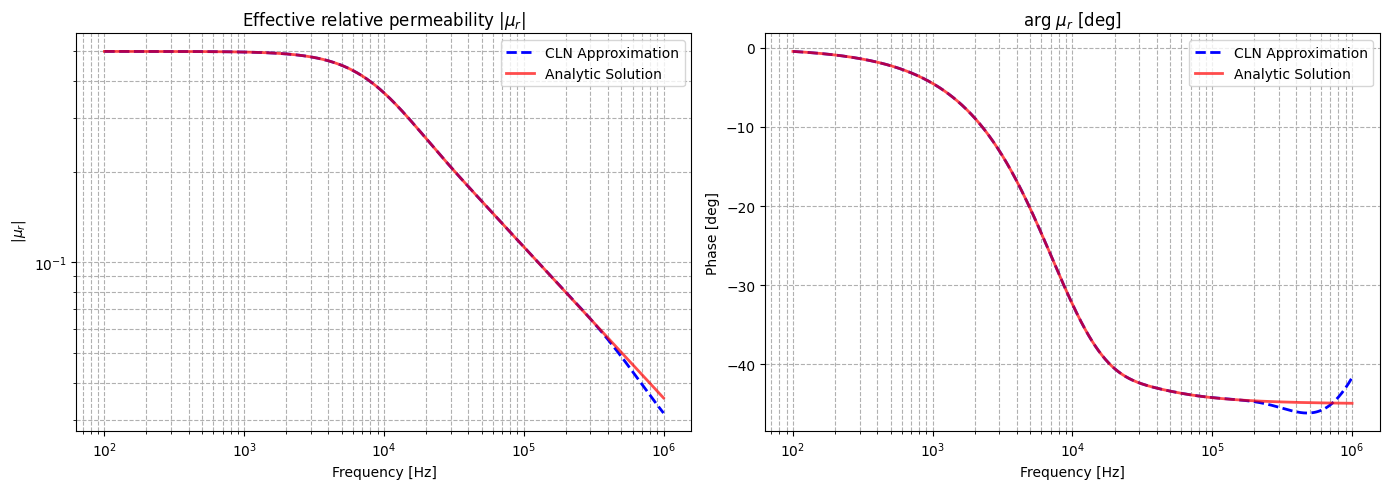

In [3]:
cln = CLN_Sphere('H', 1)
cln.displayParameters()
R, L, A, E, H, Z = cln.buildCLN('A', nmax=8)
cln.formulationH()
cln.displayE(E)
cln.displayH(H)
cln.displayZ(Z)
cln.plot_EH(E, H)
freq_list = np.logspace(2, 6, 500)
cln.plot_Z(Z, freq_list)

## T法による構築

$\mathbf{H} = \mathbf{T}$ と置く構成（円柱の `formulationT` と同じ流儀）でも、球の $H_n$ モードの梯子が組める。

- `solveAmpere`：$\nabla \times \mathbf{H} = \mathbf{J}$ と $\nabla \cdot \mathbf{B} = 0$ を、$u = r H_t$ に対する未定係数法で解く。
- `solveFaraday`：$(r e)' = r B_t$ を項別に積分して $E_\phi$ のプロファイル $e$ を得る。
- `buildCLN('T')` で梯子を組む。$\mathbf{H}$ が $(H_r, H_t)$ の2成分で $W_h$ の重みが必要なため、`buildCLN_T` は球用にオーバーライドしてある（$L$ の計算だけ $W_h$ に置き換え）。
- 厳密解も T 法で導出できる（`formulationT`）：$e$ の方程式は A 法の $A_z$ と同じで、境界条件 $e(a) + a e'(a) = s\mu a$ から $Z = e(a)$ が得られる。

結果は A 法と同一：$\kappa = 2, 5, 7, 9, \dots$（$n=1$）、$Z$ も厳密解と一致する。

# ***** Hn mode in a sphere (T formulation) *****

---

### ** analytic solution (T formulation) **

\begin{equation} k = \sqrt{\mu} \sqrt{s} \sqrt{\sigma} \end{equation}

\begin{equation} E_\phi(r) = - \frac{2 \sqrt{2} i^{\frac{3}{2}} a^{3} k \mu s \left(k r \cosh{\left(k r \right)} - \sinh{\left(k r \right)}\right)}{r^{2} \left(2 a^{2} k^{3} \left(1 - i\right) \sinh{\left(a k \right)} - 3 a k^{2} \left(1 - i\right) \cosh{\left(a k \right)} + 3 k \left(1 - i\right) \sinh{\left(a k \right)} - \sqrt{2} i^{\frac{3}{2}} \left(a k^{2} \cosh{\left(a k \right)} - k \sinh{\left(a k \right)}\right)\right)} \end{equation}

\begin{equation} Z = - \frac{2 \sqrt{2} i^{\frac{3}{2}} a \mu s \left(a k \cosh{\left(a k \right)} - \sinh{\left(a k \right)}\right)}{2 a^{2} k^{2} \left(1 - i\right) \sinh{\left(a k \right)} - 3 a k \left(1 - i\right) \cosh{\left(a k \right)} - \sqrt{2} i^{\frac{3}{2}} \left(a k \cosh{\left(a k \right)} - \sinh{\left(a k \right)}\right) + 3 \left(1 - i\right) \sinh{\left(a k \right)}} \end{equation}

... (18 outputs left out)

**【適用する置き換えの式】**

<IPython.core.display.Math object>

Eq(Z_{\text{CLN}}(s), 1/(1/(5*R_c + 1/(1/(9*R_c + 1/(1/(13*R_c + 1/(1/(L_c*s/19 + 17*R_c) + 15/(L_c*s))) + 11/(L_c*s))) + 7/(L_c*s))) + 2/(L_c*s)))

{a: 0.01, sigma: 1000000.0, mu: 4.0e-7*pi, n: 1}


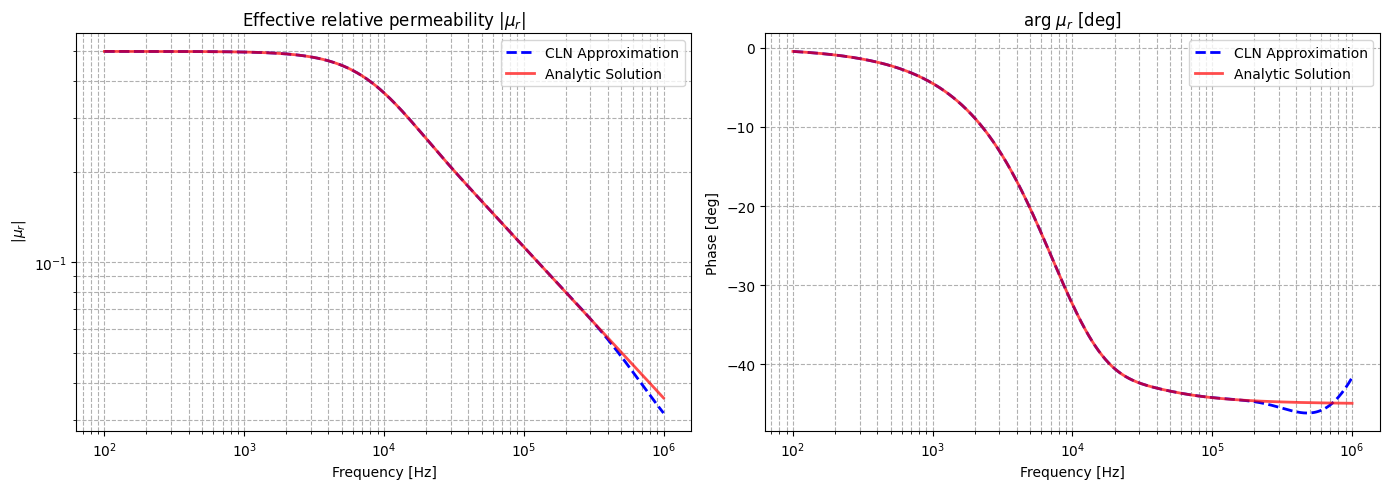

In [4]:
clnT = CLN_Sphere('H', 1)
RT, LT, TT, ET, HT, ZT = clnT.buildCLN('T', nmax=8)
clnT.formulationT()
clnT.displayE(ET)
clnT.displayH(HT)
clnT.displayZ(ZT)
freq_list = np.logspace(2, 6, 500)
clnT.plot_Z(ZT, freq_list)